# Punti 1–2 — passo temporale ottimale: taglio netto e raccordo $P_7$

:::{important} Archivio: versione a 5 punti
Questo notebook risolve i punti 1–2 della versione dell'esercizio a 5
punti (`Exercise-MD.pdf`), arrivata per errore, **non** la consegna d'esame.
La consegna è risolta nel notebook
[Exercise 1 (PART 1 + 2)](esercizio1_part1_2.ipynb); le parti di metodo utili
anche lì sono riassunte nelle
[Note tecniche](../../book/06_esercizio1_md/note_tecniche.md).
:::

Questa pagina riprende l'implementazione già fatta nella Parte 2 di
[Esercizi CMS 6](../05_molecular_dynamics/esercizi_cms6.ipynb) e la rivede
perché segua alla lettera il testo della versione a 5 punti
([archivio](../../book/06_esercizio1_md/archivio_5_punti.md)).

| | Parte 2 di `esercizi_cms6` | Qui (testo d'esame) |
|---|---|---|
| Sistema | cristallo periodico (PBC in $x$, $y$, $z$) | **cluster** isolato di 256 atomi (nessuna PBC) |
| Lunghezza di una prova | 13 ps per ogni $\Delta t$ | **5000 passi** per ogni $\Delta t$ |
| Temperature | 30, 200, 500, 2500 K | taglio netto: **50, 500 K**; $P_7$: **50, 500, 1000, 2000 K** |
| Codice | funzioni definite nel notebook | modulo `computational_course.md_p7` (Numba, con test) |

Il cambio più importante è il primo. I punti 1–3 parlano di «centro del
cluster» e «vertici del cubo», quindi gli atomi di superficie sono liberi.
Proprio questi atomi, meno legati, portano coppie oltre $r_c$ già a 500 K.

Il criterio è quello del capitolo, [](#eq:dt-criterion): $\delta E$ è la
deviazione standard di $E_\text{tot}$ dopo i primi $t_{th}=3$ ps, e un
$\Delta t$ è accettabile se $\delta E/|\langle E\rangle|<10^{-5}$.

In [1]:
import sys
from pathlib import Path


def _setup_path():
    root = Path.cwd()
    for _ in range(10):
        if (root / "pyproject.toml").exists():
            break
        root = root.parent
    for sub in ("src", "materials"):
        path = str(root / sub)
        if path not in sys.path:
            sys.path.insert(0, path)
    return root


ROOT = _setup_path()

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.ticker import NullFormatter, ScalarFormatter
from poly7 import poly7  # file del corso: materials/poly7.py

from computational_course.fcc_lattice import fcc_supercell
from computational_course.lennard_jones import lennard_jones_pair
from computational_course.md import assign_vel
from computational_course.md_p7 import lj_p7_model, max_force, production_stats, run_nve

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "font.size": 10,
        "axes.grid": True,
        "grid.alpha": 0.25,
        "axes.axisbelow": True,
    }
)

# --- parametri comuni dell'esercizio ---
EPSILON = 0.345  # eV
SIGMA = 2.644  # Å
RC = 4.5  # Å, raggio di taglio
RP = 4.2  # Å, inizio del raccordo P7 (punto 2)
T_TH_PS = 3.0  # ps, termalizzazione scartata
NSTEPS = 5000  # passi di integrazione per ogni prova
SOGLIA = 1e-5  # criterio: δE/|⟨E⟩| < SOGLIA
MASS = 108.0 * 1.66e-27 / 16.0  # massa Ag in unità di codice (eV s²/Å²)
FS = 1e-15  # s
A_AG = 4.1604  # Å, passo reticolare dei file del corso

lp = poly7(EPSILON, SIGMA, RC, RP)  # stesso ordine del file: eps, sig, rcut, rpoly
P7 = np.array([lp.A, lp.B, lp.C, lp.D, lp.E, lp.F, lp.G, lp.H])  # termini r^0 ... r^7

netto = lj_p7_model(SIGMA, EPSILON, RC)  # taglio netto in r_c
raccordo = lj_p7_model(SIGMA, EPSILON, RC, rp=RP, p7=P7)  # P7 tra r_p e r_c

# colori fissi per temperatura, uguali in tutte le pagine dell'esercizio
COLORI = {50.0: "#2a78d6", 500.0: "#eb6834", 1000.0: "#1baf7a", 2000.0: "#eda100"}
GRIGIO = "#52514e"

## 0. La cella e il modello

**La cella.** Il file `fcc100a256.txt` dell'elearning non è ancora in
`data/raw/`. Finché manca, la cella si ricostruisce con `fcc_supercell`: con
$3\times3\times3$ celle la stessa costruzione riproduce **esattamente** il file
del corso `fcc100a108.txt`. Quando il file sarà in `data/raw/`, la cella
successiva lo userà al posto della ricostruzione.

In [2]:
FILE_256 = ROOT / "data" / "raw" / "fcc100a256.txt"
ref_108 = np.loadtxt(ROOT / "data" / "raw" / "fcc100a108.txt")
ric_108, _ = fcc_supercell(A_AG, 3, 3, 3)
stessi_siti = {tuple(r) for r in np.round(ref_108, 4)} == {tuple(r) for r in np.round(ric_108, 4)}
print(f"fcc_supercell(a = {A_AG} Å, 3x3x3) coincide con fcc100a108.txt: {stessi_siti}")

if FILE_256.exists():
    pos0, origine = np.loadtxt(FILE_256), "fcc100a256.txt (elearning)"
else:
    pos0, origine = fcc_supercell(A_AG, 4, 4, 4)[0], "ricostruita con fcc_supercell(4x4x4)"
natoms = len(pos0)
lato = pos0.max(axis=0) - pos0.min(axis=0)
print(f"cella: {origine}; N = {natoms} atomi, estensione {lato[0]:.3f} Å per lato")

# distanze dei primi tre vicini rispetto a r_p e r_c
r1, r2, r3 = A_AG / np.sqrt(2), A_AG, A_AG * np.sqrt(1.5)
print(f"r1 = {r1:.3f} Å,  r2 = {r2:.3f} Å (< r_p = {RP}),  r3 = {r3:.3f} Å (> r_c = {RC})")

for nome, modello in (("taglio netto", netto), ("raccordo P7", raccordo)):
    e, f, _ = modello(pos0)
    print(f"{nome:13s}: E = {e:.4f} eV ({e / natoms:.4f} eV/atomo), F_max = {max_force(f):.3f} eV/Å")

fcc_supercell(a = 4.1604 Å, 3x3x3) coincide con fcc100a108.txt: True
cella: ricostruita con fcc_supercell(4x4x4); N = 256 atomi, estensione 14.561 Å per lato
r1 = 2.942 Å,  r2 = 4.160 Å (< r_p = 4.2),  r3 = 5.095 Å (> r_c = 4.5)
taglio netto : E = -453.4502 eV (-1.7713 eV/atomo), F_max = 0.197 eV/Å
raccordo P7  : E = -453.4502 eV (-1.7713 eV/atomo), F_max = 0.197 eV/Å


Nel reticolo ideale nessuna coppia cade tra $r_p$ e $r_c$: i secondi vicini
sono appena sotto $r_p$ e i terzi oltre $r_c$. Per questo le due energie
coincidono. Netto e $P_7$ si separano solo quando le vibrazioni portano delle
coppie nella zona del raccordo o oltre $r_c$.

Il cluster **non** è all'equilibrio: gli atomi di superficie hanno meno vicini
e sentono forze fino a circa $0.2$ eV/Å. Nei punti 1–2 il testo non chiede di
minimizzare (la *steepest descent* entra dal punto 3), quindi si parte da
questa configurazione.

**Il raccordo.** Il controllo delle condizioni [](#eq:poly-conds) usa i
coefficienti di `poly7.py`.

In [3]:
from fractions import Fraction

polyval, polyder = np.polynomial.polynomial.polyval, np.polynomial.polynomial.polyder


def lj_derivate(r):
    # φ_LJ e le prime tre derivate in r
    s6, s12 = SIGMA**6, SIGMA**12
    return 4.0 * EPSILON * np.array(
        [
            s12 / r**12 - s6 / r**6,
            -12 * s12 / r**13 + 6 * s6 / r**7,
            156 * s12 / r**14 - 42 * s6 / r**8,
            -2184 * s12 / r**15 + 336 * s6 / r**9,
        ]
    )


tabella = pd.DataFrame(
    {
        "P7^(k)(r_p)": [polyval(RP, polyder(P7, k)) for k in range(4)],
        "φ_LJ^(k)(r_p)": lj_derivate(RP),
        "P7^(k)(r_c)": [polyval(RC, polyder(P7, k)) for k in range(4)],
    },
    index=pd.Index(range(4), name="k"),
)
display(tabella.style.format("{:.6e}").set_caption("Condizioni di raccordo (k = ordine della derivata)"))

# quanto rumore numerico ha il P7 in doppia precisione?
r_test = np.linspace(RP, RC, 301)
esatto = np.array([float(sum(Fraction(c) * Fraction(x) ** k for k, c in enumerate(P7))) for x in r_test])
rumore = np.abs(polyval(r_test, P7) - esatto).max()
print(f"coefficienti: da {np.abs(P7).min():.1e} a {np.abs(P7).max():.1e}, segni alterni")
print(f"errore di arrotondamento nel valutare P7 su [r_p, r_c]: fino a {rumore:.1e} eV")
print(f"residuo in r_c (P7 esatto con questi coefficienti): {esatto[-1]:.1e} eV")
print(f"salto del taglio netto in r_c: φ_LJ(r_c) = {lennard_jones_pair(RC, SIGMA, EPSILON):.4f} eV")

,P7^(k)(r_p),φ_LJ^(k)(r_p),P7^(k)(r_c)
k,,,
0,-8.054981e-02,-8.054592e-02,-5.662441e-06
1,1.074241e-01,1.074285e-01,-5.185604e-06
2,-1.572302e-01,-1.572273e-01,-3.278255e-06
3,2.319404e-01,2.319419e-01,-1.668930e-06


coefficienti: da 6.0e+03 a 2.8e+08, segni alterni
errore di arrotondamento nel valutare P7 su [r_p, r_c]: fino a 1.0e-06 eV
residuo in r_c (P7 esatto con questi coefficienti): -6.0e-06 eV
salto del taglio netto in r_c: φ_LJ(r_c) = -0.0544 eV


Le condizioni sono rispettate fino a qualche $10^{-6}$, non fino alla
precisione di macchina. Il motivo è numerico: i coefficienti arrivano a
$10^{8}$ con segni alterni, mentre il polinomio vale meno di $0.1$ eV, quindi
nella somma si perdono molte cifre per cancellazione. Il residuo in $r_c$ è
però circa $10^4$ volte più piccolo del salto del taglio netto, e per questo
esercizio è trascurabile. (Per lo stesso motivo un test che confronta le forze
con le differenze finite dell'energia deve usare un passo $h$ non troppo
piccolo.)

## 1. Una prova

Ogni prova assegna le velocità a $T_\text{ini}$ (stesso seme per tutte),
integra 5000 passi in NVE con *velocity Verlet* e calcola le medie dopo
$t_{th}=3$ ps. Conta anche gli **attraversamenti di $r_c$**, cioè quante volte
una coppia entra o esce dal raggio di taglio: con il taglio netto ogni
attraversamento è un salto di energia.

Con 5000 passi la durata dipende da $\Delta t$: a 1 fs la prova dura 5 ps e
restano 2 ps per la statistica, a 25 fs dura 125 ps.

In [4]:
DTS_FS = [1, 2, 3, 4, 5, 6, 7, 8, 10, 12, 15, 18, 20, 25]  # Δt [fs], intervallo [1, 25] fs


def prova(modello, t_ini, dt_fs, nsteps=NSTEPS, seed=33282739):
    # una MD NVE dal cluster pos0; medie dopo T_TH_PS
    vel = assign_vel(natoms, MASS, t_ini, seed=seed)
    res = run_nve(pos0, vel, MASS, dt_fs * FS, nsteps, modello)
    ntherm = int(round(T_TH_PS * 1000.0 / dt_fs))
    return {
        "T_ini": t_ini,
        "dt_fs": dt_fs,
        **production_stats(res, ntherm),
        "n_cross": res["n_cross"],
        "stabile": res["stable"],
        "res": res,
    }


def scansione(modello, t_ini, dts=DTS_FS):
    return [prova(modello, t_ini, dt) for dt in dts]


def dt_validi(prove):
    # i Δt con δE/|⟨E⟩| < SOGLIA: nei grafici, i punti sotto la linea
    return [p["dt_fs"] for p in prove if p["dE_rel"] < SOGLIA]


def dt_ottimale(prove):
    # il più grande Δt valido (NaN se nessuno)
    ok = dt_validi(prove)
    return max(ok) if ok else np.nan


def testo_ottimale(prove):
    return f"{dt_ottimale(prove):g} fs" if dt_validi(prove) else "nessuno"


def testo_validi(prove):
    # "1–6 fs" se i validi sono i primi Δt provati, altrimenti l'elenco
    ok = dt_validi(prove)
    if not ok:
        return "nessuno"
    if ok == DTS_FS[: len(ok)] and len(ok) > 1:
        return f"{ok[0]:g}–{ok[-1]:g} fs"
    return ", ".join(f"{dt:g}" for dt in ok) + " fs"


ROSSO = "color: #c0392b; font-weight: bold"


def tabella_scansione(scansioni, titolo):
    # righe Δt; per ogni T_ini: δE/|⟨E⟩| (rosso se fuori soglia), ⟨T⟩, attraversamenti
    blocchi = {}
    for t_ini, prove in scansioni.items():
        blocchi[f"{t_ini:g} K"] = pd.DataFrame(
            {
                "δE/|⟨E⟩|": [p["dE_rel"] for p in prove],
                "⟨T⟩ [K]": [p["T_mean"] for p in prove],
                "attrav. r_c": [p["n_cross"] for p in prove],
            },
            index=pd.Index([p["dt_fs"] for p in prove], name="Δt [fs]"),
        )
    tab = pd.concat(blocchi, axis=1)
    colonne = {nome: [c for c in tab.columns if c[1] == nome] for nome in tab.columns.levels[1]}
    return (
        tab.style.format("{:.1e}", subset=colonne["δE/|⟨E⟩|"], na_rep="instabile")
        .format("{:.0f}", subset=colonne["⟨T⟩ [K]"], na_rep="—")
        .format("{:d}", subset=colonne["attrav. r_c"])
        .map(lambda v: "" if v < SOGLIA else ROSSO, subset=colonne["δE/|⟨E⟩|"])
        .set_caption(titolo)
    )


def grafico_scansione(ax, scansioni, stile, etichetta):
    for t_ini, prove in scansioni.items():
        ax.plot(
            [p["dt_fs"] for p in prove],
            [p["dE_rel"] for p in prove],
            stile,
            color=COLORI[t_ini],
            ms=4,
            lw=1.5,
            label=f"$T_{{ini}}$ = {t_ini:g} K, {etichetta}",
        )


def assi_scansione(ax, titolo):
    ax.axhline(SOGLIA, color=GRIGIO, lw=1.2, ls="--", label=r"soglia $10^{-5}$")
    ax.set_xscale("log")
    ax.set_yscale("log")
    y_lo, y_hi = ax.get_ylim()
    ax.axhspan(y_lo, SOGLIA, color="0.9", lw=0, zorder=0, label="Δt validi: sotto la linea")
    ax.set_ylim(y_lo, y_hi)
    ax.set_xticks([1, 2, 3, 5, 8, 10, 15, 20, 25])
    ax.xaxis.set_major_formatter(ScalarFormatter())
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set(xlabel=r"$\Delta t$ [fs]", ylabel=r"$\delta E/|\langle E\rangle|$", title=titolo)
    ax.legend(fontsize=8.5)

## 2. Punto 1 — taglio netto

**Testo.** Con il taglio netto, trovare il $\Delta t$ ottimale per
$T_\text{ini}=50$ K, provando passi tra 1 e 25 fs con 5000 passi ciascuno.
Ripetere a $T_\text{ini}=500$ K e mostrare che lì il criterio non si può
rispettare, comunque si riduca il passo.

In [5]:
punto1 = {t: scansione(netto, t) for t in (50.0, 500.0)}
display(tabella_scansione(punto1, "Punto 1 — taglio netto (in rosso: fuori soglia)"))
for t, prove in punto1.items():
    print(f"T_ini = {t:g} K: Δt validi (sotto la linea) = {testo_validi(prove)}, "
          f"Δt ottimale = {testo_ottimale(prove)}")

T_ini = 50 K: Δt validi (sotto la linea) = 1–20 fs, Δt ottimale = 20 fs
T_ini = 500 K: Δt validi (sotto la linea) = nessuno, Δt ottimale = nessuno


**«Comunque si riduca il passo».** L'intervallo richiesto parte da 1 fs. Per
mostrare che a 500 K il problema non è il passo, si scende anche sotto, a 0.5
e 0.25 fs. Lì 5000 passi non bastano a superare $t_{th}$, quindi si tiene la
**durata** di 5 ps (la stessa della prova a 1 fs) e si aumentano i passi.

Δt =  0.50 fs (10000 passi): δE/|⟨E⟩| = 1.57e-04, attraversamenti di r_c = 247
Δt =  0.25 fs (20000 passi): δE/|⟨E⟩| = 1.55e-04, attraversamenti di r_c = 246
Δt =  1.00 fs ( 5000 passi): δE/|⟨E⟩| = 1.56e-04, attraversamenti di r_c = 243


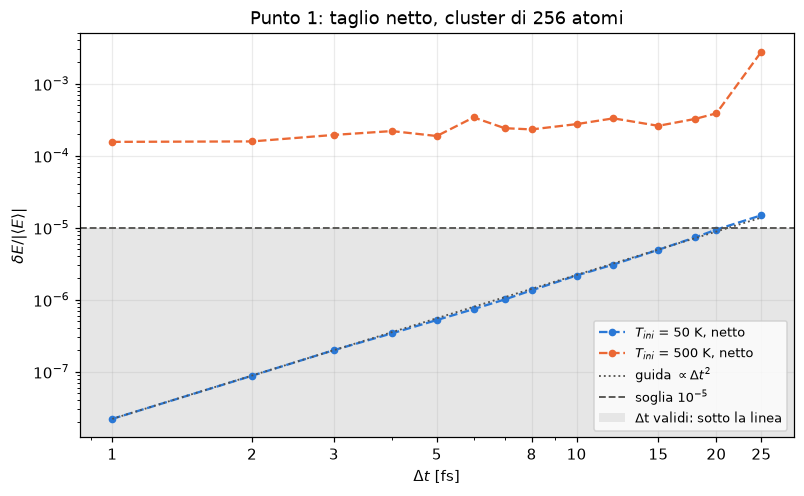

In [6]:
sotto_fs = [prova(netto, 500.0, dt, nsteps=int(round(5000 / dt))) for dt in (0.5, 0.25)]
for p in sotto_fs + [punto1[500.0][0]]:
    print(
        f"Δt = {p['dt_fs']:5.2f} fs ({int(round(5000 / p['dt_fs'])):5d} passi): "
        f"δE/|⟨E⟩| = {p['dE_rel']:.2e}, attraversamenti di r_c = {p['n_cross']}"
    )

fig, ax = plt.subplots(figsize=(7.2, 4.4), constrained_layout=True)
grafico_scansione(ax, punto1, "o--", "netto")
dts = np.array(DTS_FS, dtype=float)
guida = punto1[50.0][0]["dE_rel"] * (dts / dts[0]) ** 2
ax.plot(dts, guida, ":", color=GRIGIO, lw=1.2, label=r"guida $\propto\Delta t^2$")
assi_scansione(ax, "Punto 1: taglio netto, cluster di 256 atomi")
plt.show()

**Lettura.**

- **50 K.** Nessuna coppia attraversa $r_c$ (colonna «attrav. r_c» a zero) e
  $\delta E/|\langle E\rangle|$ cresce come $\Delta t^2$, parallelo alla
  guida puntinata. L'errore è quindi solo quello dell'integratore. Sono
  **validi**, cioè sotto la linea, tutti i passi da 1 a 20 fs: l'ottimale è
  **20 fs** (circa $9\times10^{-6}$, vicino alla soglia: vedi §4), mentre a
  25 fs si sale a $1.5\times10^{-5}$.
- **500 K.** Già a 1 fs $\delta E/|\langle E\rangle|\approx1.6\times10^{-4}$,
  16 volte la soglia, e il valore **non scende** né a 0.5 né a 0.25 fs:
  **nessun** passo è valido, tutti i punti restano sopra la linea. In
  5 ps più di 200 coppie attraversano $r_c$, e a ogni attraversamento
  l'energia salta di $|\phi_{LJ}(r_c)|=0.054$ eV, qualunque sia il passo. È
  un errore del **modello**, non dell'integratore. Ridurre $\Delta t$ riduce
  solo la parte $\propto\Delta t^2$, che qui è già trascurabile.
- Gli attraversamenti crescono con $\Delta t$ solo perché, a 5000 passi
  fissi, la prova dura di più (125 ps a 25 fs).
- A 50 K si ottiene $\langle T\rangle\approx28$ K, non $T_\text{ini}/2=25$ K.
  Il cluster parte fuori equilibrio: rilassando, trasforma energia potenziale
  in cinetica e si scalda. Il problema si risolve partendo da un minimo con
  la [steepest descent](steepest_descent.ipynb), come chiede il punto 3.

## 3. Punto 2 — raccordo $P_7$

**Testo.** Con il raccordo $P_7$ tra $r_p=4.2$ Å e $r_c$ (forze adattate di
conseguenza), verificare che a $T_\text{ini}=50$ K la simulazione sia
coerente con quella a taglio netto. Trovare poi il $\Delta t$ ottimale per
$T_\text{ini}=500$, $1000$ e $2000$ K.

### 3.1 Coerenza a 50 K

In [7]:
p7_50 = scansione(raccordo, 50.0)
righe = []
for pn, pp in zip(punto1[50.0], p7_50):
    righe.append(
        {
            "Δt [fs]": pn["dt_fs"],
            "δE netto": pn["dE_rel"],
            "δE P7": pp["dE_rel"],
            "rapporto": pn["dE_rel"] / pp["dE_rel"],
            "max |Δr| finale [Å]": np.abs(pn["res"]["pos"] - pp["res"]["pos"]).max(),
            "max |ΔE_tot(t)| [eV]": np.nanmax(np.abs(pn["res"]["etot"] - pp["res"]["etot"])),
        }
    )
coerenza = pd.DataFrame(righe).set_index("Δt [fs]")
display(
    coerenza.style.format(
        {
            "δE netto": "{:.2e}",
            "δE P7": "{:.2e}",
            "rapporto": "{:.3f}",
            "max |Δr| finale [Å]": "{:.1e}",
            "max |ΔE_tot(t)| [eV]": "{:.1e}",
        }
    ).set_caption("T_ini = 50 K: taglio netto contro P7, stesse velocità iniziali")
)
print(f"Δt ottimale a 50 K: netto {dt_ottimale(punto1[50.0]):g} fs, P7 {dt_ottimale(p7_50):g} fs")

,δE netto,δE P7,rapporto,max |Δr| finale [Å],max |ΔE_tot(t)| [eV]
Δt [fs],,,,,
1,2.22e-08,1.02e-07,0.218,1.8e-01,4.9e-04
2,8.81e-08,1.31e-07,0.670,2.0e-01,5.1e-04
3,2.00e-07,2.21e-07,0.903,1.2e-01,7.6e-04
4,3.41e-07,3.69e-07,0.925,1.2e-01,1.1e-03
5,5.23e-07,5.71e-07,0.916,1.3e-01,1.6e-03
6,7.42e-07,8.04e-07,0.923,2.3e-01,2.1e-03
7,1.01e-06,1.07e-06,0.944,1.2e-01,2.6e-03
8,1.35e-06,1.41e-06,0.960,1.6e-01,3.5e-03
10,2.17e-06,2.23e-06,0.975,1.4e-01,5.0e-03


Δt ottimale a 50 K: netto 20 fs, P7 20 fs


**Lettura.** Le due traiettorie **non** sono identiche: dopo 5000 passi le
posizioni differiscono di 0.1–0.2 Å. A 50 K alcune coppie entrano davvero
nella zona del raccordo, perché ai bordi del cluster non rilassato i secondi
vicini oscillano attorno a $r_p$. La dinamica è caotica e amplifica anche una
differenza minima nelle forze. La **statistica** però coincide: stesso
$\langle T\rangle$, stesso $\delta E$ entro pochi punti percentuali per
$\Delta t\ge3$ fs, stesso passo ottimale. «Coerente» vuol dire questo: stesse
medie, non stessa traiettoria.

**Il pavimento del $P_7$ a 1–2 fs.** Con i passi più piccoli il $P_7$ si
ferma a circa $10^{-7}$, mentre il taglio netto scende a $2\times10^{-8}$. La
causa è il raccordo in $r_p$: con i coefficienti del corso
$P_7(r_p)-\phi_{LJ}(r_p)\approx-4\times10^{-6}$ eV (tabella del §0), quindi
ogni coppia che attraversa $r_p$ fa un piccolissimo salto di energia. La
cella seguente lo verifica in due modi: conta gli attraversamenti di $r_p$ e
ripete la prova correggendo **solo** $A$, in modo che
$P_7(r_p)=\phi_{LJ}(r_p)$. È solo una diagnosi: il pavimento resta 100 volte
sotto la soglia, e per l'esercizio si usano i coefficienti del corso così come
sono.

In [8]:
A_corretto = P7.copy()
A_corretto[0] += lennard_jones_pair(RP, SIGMA, EPSILON) - polyval(RP, P7)

iu, ju = np.triu_indices(natoms, k=1)
for nome, coeff in (("P7 del corso", P7), ("P7 con A corretto", A_corretto)):
    modello = lj_p7_model(SIGMA, EPSILON, RC, rp=RP, p7=coeff)
    vel = assign_vel(natoms, MASS, 50.0)
    res = run_nve(pos0, vel, MASS, 1.0 * FS, NSTEPS, modello, sample_every=1)
    dist = np.linalg.norm(res["frames"][:, iu] - res["frames"][:, ju], axis=-1)
    oltre_rp = dist > RP  # a 50 K nessuna coppia supera r_c
    salto = polyval(RP, coeff) - lennard_jones_pair(RP, SIGMA, EPSILON)
    print(
        f"{nome:18s}: P7(r_p) - φ_LJ(r_p) = {salto:+.1e} eV, "
        f"attraversamenti di r_p = {np.count_nonzero(oltre_rp[1:] != oltre_rp[:-1])}, "
        f"δE/|⟨E⟩| a 1 fs = {production_stats(res, 3000)['dE_rel']:.1e}"
    )

P7 del corso      : P7(r_p) - φ_LJ(r_p) = -3.9e-06 eV, attraversamenti di r_p = 7691, δE/|⟨E⟩| a 1 fs = 1.0e-07


P7 con A corretto : P7(r_p) - φ_LJ(r_p) = +1.4e-08 eV, attraversamenti di r_p = 7691, δE/|⟨E⟩| a 1 fs = 3.0e-08


### 3.2 Passo ottimale a 500, 1000 e 2000 K

P7, T_ini = 50 K: Δt validi (sotto la linea) = 1–20 fs, Δt ottimale = 20 fs
P7, T_ini = 500 K: Δt validi (sotto la linea) = 1–6 fs, Δt ottimale = 6 fs
P7, T_ini = 1000 K: Δt validi (sotto la linea) = 1–4 fs, Δt ottimale = 4 fs
P7, T_ini = 2000 K: Δt validi (sotto la linea) = 1–3 fs, Δt ottimale = 3 fs


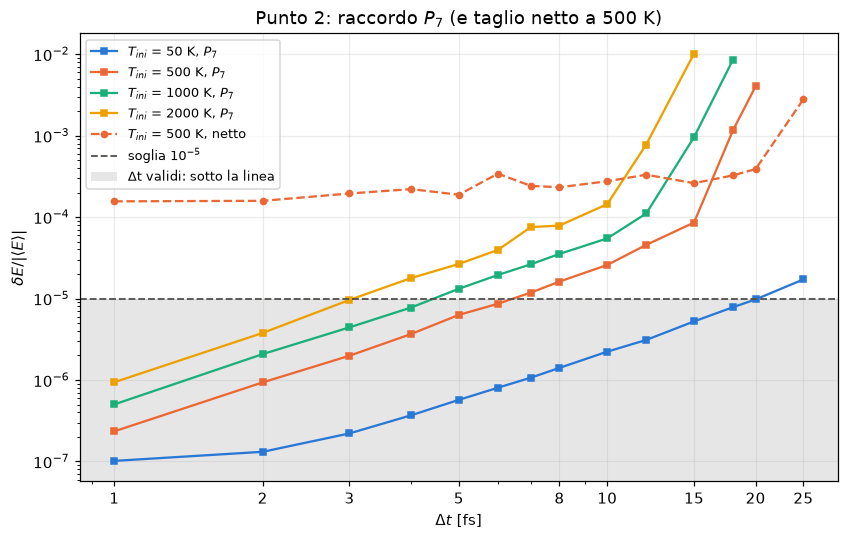

In [9]:
punto2 = {50.0: p7_50} | {t: scansione(raccordo, t) for t in (500.0, 1000.0, 2000.0)}
display(tabella_scansione({t: punto2[t] for t in (500.0, 1000.0, 2000.0)},
                          "Punto 2 — raccordo P7 (in rosso: fuori soglia)"))
for t, prove in punto2.items():
    print(f"P7, T_ini = {t:g} K: Δt validi (sotto la linea) = {testo_validi(prove)}, "
          f"Δt ottimale = {testo_ottimale(prove)}")

fig, ax = plt.subplots(figsize=(7.6, 4.8), constrained_layout=True)
grafico_scansione(ax, punto2, "s-", "$P_7$")
grafico_scansione(ax, {500.0: punto1[500.0]}, "o--", "netto")
assi_scansione(ax, "Punto 2: raccordo $P_7$ (e taglio netto a 500 K)")
plt.show()

**Lettura.**

- Con il $P_7$ il criterio torna rispettabile anche a 500 K: a 1 fs
  $\delta E/|\langle E\rangle|$ scende a qualche $10^{-7}$, mentre con il
  taglio netto (curva arancio tratteggiata) resta a $1.6\times10^{-4}$. Le
  coppie attraversano ancora $r_c$, ma ora non costa nulla, perché in $r_c$
  energia e forza sono già nulle.
- **Passi validi**, cioè i punti sotto la linea (fascia grigia): da 1 a
  6 fs a 500 K, da 1 a 4 fs a 1000 K, da 1 a 3 fs a 2000 K. A 50 K sono
  validi tutti i passi da 1 a 20 fs, come con il taglio netto.
- Il passo ottimale è l'ultimo valido e scende con la temperatura: **6 fs** a
  500 K, **4 fs** a 1000 K, **3 fs** a 2000 K. Più gli atomi sono veloci, più
  strada fanno in un passo, e più il passo va ridotto. Finché la simulazione è
  stabile, l'errore segue $\Delta t^2$.
- Con passi grandi e temperatura alta la simulazione **diverge**
  («instabile»): a 2000 K già da 18 fs.
- A 2000 K e 3 fs $\delta E/|\langle E\rangle|$ vale circa $1.0\times10^{-5}$,
  cioè è a ridosso della soglia: il §4 controlla se il risultato regge con
  altre velocità iniziali.

Il grafico qui sotto mostra $E_\text{tot}(t)$ a $500$ K con lo stesso passo
di 1 fs per i due potenziali.

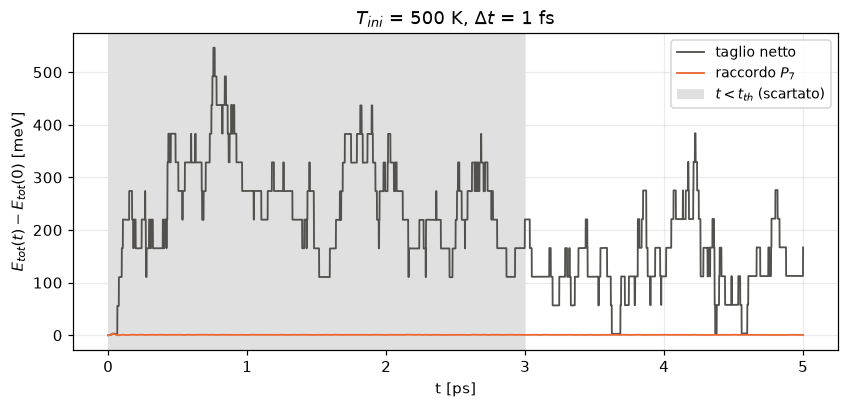

In [10]:
fig, ax = plt.subplots(figsize=(7.6, 3.6), constrained_layout=True)
for p, nome, colore in ((punto1[500.0][0], "taglio netto", GRIGIO), (punto2[500.0][0], "raccordo $P_7$", COLORI[500.0])):
    res = p["res"]
    ax.plot(res["time_ps"], (res["etot"] - res["etot"][0]) * 1e3, lw=1.2, color=colore, label=nome)
ax.axvspan(0, T_TH_PS, color="0.88", lw=0, label="$t < t_{th}$ (scartato)")
ax.set(xlabel="t [ps]", ylabel=r"$E_{tot}(t)-E_{tot}(0)$ [meV]",
       title=r"$T_{ini}$ = 500 K, $\Delta t$ = 1 fs")
ax.legend(fontsize=9)
plt.show()

Con il taglio netto $E_\text{tot}$ procede **a gradini**: ogni gradino è una
coppia che attraversa $r_c$, e i gradini si sommano come una passeggiata
casuale. Con il $P_7$, sulla stessa scala, la curva resta piatta.

## 4. Quanto è robusto il passo ottimale?

$\delta E/|\langle E\rangle|$ viene da **una** traiettoria, quindi ha un
errore statistico: con velocità iniziali diverse (un altro seme) cambia di
qualche punto percentuale. Quando il valore è vicino a $10^{-5}$, questo basta
a spostare il passo ottimale. Per ogni caso si ripete quindi la prova con
**4 semi**, partendo dal passo ottimale trovato sopra e scendendo finché
**tutti** i semi rispettano il criterio.

In [11]:
SEMI = (33282739, 20260101, 555000111, 987654321)
casi = {("netto", 50.0): (netto, punto1[50.0])} | {
    ("P7", t): (raccordo, punto2[t]) for t in (50.0, 500.0, 1000.0, 2000.0)
}
righe, consigliato = [], {}
for (nome, t_ini), (modello, prove) in casi.items():
    i = DTS_FS.index(dt_ottimale(prove))
    while i >= 0:
        dt = DTS_FS[i]
        de = np.array([prova(modello, t_ini, dt, seed=s)["dE_rel"] for s in SEMI])
        tutti = bool(np.all(de < SOGLIA))
        righe.append({"potenziale": nome, "T_ini [K]": t_ini, "Δt [fs]": dt,
                      "δE min": de.min(), "δE medio": de.mean(), "δE max": de.max(),
                      "tutti sotto soglia": "sì" if tutti else "no"})
        if tutti:
            consigliato[nome, t_ini] = dt
            break
        i -= 1
robustezza = pd.DataFrame(righe).set_index(["potenziale", "T_ini [K]", "Δt [fs]"])
display(
    robustezza.style.format("{:.2e}", subset=["δE min", "δE medio", "δE max"])
    .format_index("{:g}", level=[1, 2])
    .set_caption(f"δE/|⟨E⟩| su {len(SEMI)} semi delle velocità iniziali")
)

**Lettura.** In tutti i casi il passo ottimale regge con i 4 semi: nessun
seme lo porta sopra la soglia. Le dispersioni tra semi sono di pochi punti
percentuali, ma i margini più stretti sono proprio di quest'ordine: circa
$4\%$ a 2000 K con 3 fs e meno del $3\%$ con il $P_7$ a 50 K e 20 fs. Il
punto 3 chiede di usare i passi ottimali del punto 2, e sono questi. Dove il
margine è di pochi punti percentuali, scegliere il passo immediatamente più
piccolo costa poco tempo e mette al riparo da sorprese.

## 5. Riepilogo: i passi da usare nel punto 3

In [12]:
tutte = [("netto", t, punto1[t]) for t in punto1] + [("P7", t, punto2[t]) for t in punto2]
riepilogo = pd.DataFrame(
    [
        {
            "potenziale": nome,
            "T_ini [K]": t,
            "Δt validi": testo_validi(prove),
            "Δt ottimale [fs]": dt_ottimale(prove),
            "Δt consigliato [fs]": consigliato.get((nome, t), np.nan),
            "⟨T⟩ a 1 fs [K]": prove[0]["T_mean"],
            "attrav. r_c a 1 fs": prove[0]["n_cross"],
        }
        for nome, t, prove in tutte
    ]
).set_index(["potenziale", "T_ini [K]"])
display(
    riepilogo.style.format("{:g}", subset=["Δt ottimale [fs]", "Δt consigliato [fs]"], na_rep="nessuno")
    .format("{:.1f}", subset=["⟨T⟩ a 1 fs [K]"])
    .format("{:d}", subset=["attrav. r_c a 1 fs"])
    .format_index("{:g}", level=1)
    .set_caption("validi: δE/|⟨E⟩| < 1e-5 (sotto la linea); ottimale: il più grande valido; "
                 "consigliato: valido con tutti i 4 semi")
)